# Experiment 1: soft-voting ensembles

Can averaging different models improve on Logistic Regression? Compare **equal voting** with **weighted voting** using Logistic Regression, Random Forest, XGBoost, and Extra Trees.

Use the original five outer folds and complete-case cohorts. Weighted voting chooses a small weight combination by inner-fold log loss, entirely within the outer training participants. The decision threshold stays at 0.5.

**Status: written, not executed by the assistant.** Run cells from top to bottom. This notebook does not run software tests. CPU is sufficient. It will take longer than the original run because each outer fold includes inner cross-validation.

These are exploratory follow-up experiments on an already inspected cohort. A higher score is not guaranteed and would not constitute independent confirmation.

## 1. Locate the project

Locally, open this notebook in Jupyter using the project's Python environment. In Colab, upload the updated project files to your private Drive folder first. See `docs/ensembles.md` for the minimum files, including the saved baseline cohort CSVs and manifest.

The cell below mounts Drive only when **you** run it in Colab. Edit `PROJECT_ROOT` if your folder has a different location.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None  # Or set an absolute local project path.
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'src/scripts/train_models.py').is_file()), None)
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
if ROOT is None or not (ROOT / 'src/scripts/ensemble_models.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
print('Project:', ROOT)


Project: /Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Dependencies

Skip the next cell if the modeling packages are already installed in this notebook's environment. If installation requests a kernel restart, restart and begin again at the project-path cell. No new model library is needed beyond the original requirements.

In [2]:
requirements_file = str(ROOT / 'requirements-modeling.txt')
%pip install -r "{requirements_file}"



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Freeze the experiment settings

- Evaluate the broader clinical reference, matched clinical, and matched clinical + APOE experiments.
- Refit all four individual models as same-run references. Their hyperparameters are fixed.
- Use three inner folds to obtain training-only, out-of-fold probabilities.
- Compare equal weights with weights in steps of 0.25 chosen by inner log loss. A single-model weight of 1 is allowed.
- Report accuracy, precision, sensitivity, specificity, F1, balanced accuracy, AUROC, average precision, Brier score, and confusion counts.
- Report paired bootstrap intervals against same-run Logistic Regression. Do not choose weights or thresholds from outer results.

Keep the settings fixed before execution. A rerun requires a new `run_name`; existing outputs are never overwritten.

In [3]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image

sys.path.insert(0, str(ROOT / 'src/scripts'))
from ensemble_models import load_inputs, run_experiment

cfg = json.loads((ROOT / 'config/ensembles.json').read_text())
METHOD = 'voting'
REPORT = ROOT / 'reports/modeling' / cfg['run_name'] / METHOD
baseline_manifest, cohorts = load_inputs(cfg)
display(pd.DataFrame([{'experiment': name, 'participants': len(frame),
                       'converters': int(frame.label.sum()),
                       'nonconverters': int((frame.label == 0).sum())}
                      for name, frame in cohorts.items()]))
print(json.dumps(cfg, indent=2))


,experiment,participants,converters,nonconverters
0,clinical_reference,589,216,373
1,matched_clinical,222,118,104
2,matched_fusion,222,118,104


{
  "baseline_run": "artifacts/modeling/complete_cases",
  "run_name": "ensemble_v1",
  "experiments": [
    "clinical_reference",
    "matched_clinical",
    "matched_fusion"
  ],
  "seed": 42,
  "inner_folds": 3,
  "threshold": 0.5,
  "bootstrap_repetitions": 1000,
  "base_models": [
    "logistic_regression",
    "random_forest",
    "xgboost",
    "extra_trees"
  ],
  "extra_trees": {
    "n_estimators": 300,
    "max_depth": 8,
    "min_samples_leaf": 3,
    "max_features": "sqrt",
    "n_jobs": 1
  },
  "voting_weight_step": 0.25,
  "stacking_C": 0.1
}


## 4. Train

This is the cell that starts model fitting. Preprocessing is inside each base model's pipeline, including within inner folds. Models, participant predictions, inner-fold predictions, and manifests remain in the private artifacts directory. Neither the original baseline files nor their reports are modified.

In [4]:
results = run_experiment(cfg, method=METHOD)


voting: clinical_reference, outer fold 1/5
voting: clinical_reference, outer fold 2/5
voting: clinical_reference, outer fold 3/5
voting: clinical_reference, outer fold 4/5
voting: clinical_reference, outer fold 5/5
voting: matched_clinical, outer fold 1/5
voting: matched_clinical, outer fold 2/5
voting: matched_clinical, outer fold 3/5
voting: matched_clinical, outer fold 4/5
voting: matched_clinical, outer fold 5/5
voting: matched_fusion, outer fold 1/5
voting: matched_fusion, outer fold 2/5
voting: matched_fusion, outer fold 3/5
voting: matched_fusion, outer fold 4/5
voting: matched_fusion, outer fold 5/5
Writing metrics and paired bootstrap comparisons.
Finished: reports/modeling/ensemble_v1/voting


## 5. Read the results

If this run is already complete, skip the training cell and read its results here. Percentages are used for classification metrics. AUROC, average precision, and Brier retain their 0-1 scales. Compare methods within the same experiment; the broader clinical cohort is different from the matched cohort.

In [5]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity',
           'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])


,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,random_forest,589,84.0%,80.5%,74.5%,89.5%,77.4%,82.0%,0.905,0.849,0.120
2,clinical_reference,xgboost,589,82.7%,78.2%,73.1%,88.2%,75.6%,80.7%,0.903,0.843,0.120
3,clinical_reference,extra_trees,589,83.4%,80.4%,72.2%,89.8%,76.1%,81.0%,0.903,0.845,0.124
4,clinical_reference,equal_voting,589,83.7%,79.7%,74.5%,89.0%,77.0%,81.8%,0.913,0.862,0.113
5,clinical_reference,weighted_voting,589,84.6%,80.8%,75.9%,89.5%,78.3%,82.7%,0.912,0.865,0.112
6,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
7,matched_clinical,random_forest,222,79.3%,78.6%,83.9%,74.0%,81.1%,79.0%,0.868,0.879,0.151
8,matched_clinical,xgboost,222,79.3%,80.0%,81.4%,76.9%,80.7%,79.1%,0.870,0.882,0.148
9,matched_clinical,extra_trees,222,77.5%,77.0%,82.2%,72.1%,79.5%,77.2%,0.864,0.874,0.157


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,random_forest,334,39,55,161
2,clinical_reference,xgboost,329,44,58,158
3,clinical_reference,extra_trees,335,38,60,156
4,clinical_reference,equal_voting,332,41,55,161
5,clinical_reference,weighted_voting,334,39,52,164
6,matched_clinical,logistic_regression,82,22,21,97
7,matched_clinical,random_forest,77,27,19,99
8,matched_clinical,xgboost,80,24,22,96
9,matched_clinical,extra_trees,75,29,21,97


## 6. Is the improvement convincing?

Differences below are **ensemble minus Logistic Regression**, measured on the same participants. Multiply an accuracy difference by 100 to express percentage points. Positive accuracy/AUROC/AP and negative Brier favor the ensemble. If an interval spans zero, the improvement is uncertain under this bootstrap.

Intervals condition on the saved predictions, do not capture all retraining uncertainty, and are not adjusted for multiple comparisons. `ensemble_parameters.csv` shows each outer fold's selected weights and inner training loss; those inner losses are not final performance estimates.

,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,equal_voting,logistic_regression,auroc,0.0011,-0.0080,0.0105,1000
1,clinical_reference,equal_voting,logistic_regression,average_precision,0.0097,-0.0111,0.0360,1000
2,clinical_reference,equal_voting,logistic_regression,brier_score,0.0031,-0.0027,0.0084,1000
3,clinical_reference,equal_voting,logistic_regression,accuracy,-0.0068,-0.0272,0.0136,1000
4,clinical_reference,weighted_voting,logistic_regression,auroc,0.0002,-0.0076,0.0086,1000
5,clinical_reference,weighted_voting,logistic_regression,average_precision,0.0131,-0.0063,0.0357,1000
6,clinical_reference,weighted_voting,logistic_regression,brier_score,0.0021,-0.0027,0.0066,1000
7,clinical_reference,weighted_voting,logistic_regression,accuracy,0.0017,-0.0170,0.0221,1000
8,matched_clinical,equal_voting,logistic_regression,auroc,-0.0099,-0.0309,0.0084,1000
9,matched_clinical,equal_voting,logistic_regression,average_precision,-0.0144,-0.0346,0.0051,1000


,experiment,fold,inner_log_loss,logistic_regression,random_forest,xgboost,extra_trees
0,clinical_reference,1,0.3547,0.50,0.25,0.25,0.00
1,clinical_reference,2,0.3686,0.25,0.50,0.25,0.00
2,clinical_reference,3,0.3476,0.50,0.25,0.25,0.00
3,clinical_reference,4,0.3562,0.25,0.25,0.50,0.00
4,clinical_reference,5,0.3874,0.50,0.50,0.00,0.00
5,matched_clinical,1,0.4831,0.25,0.75,0.00,0.00
6,matched_clinical,2,0.4561,0.50,0.25,0.25,0.00
7,matched_clinical,3,0.4112,0.50,0.00,0.50,0.00
8,matched_clinical,4,0.4527,0.75,0.25,0.00,0.00
9,matched_clinical,5,0.4282,0.75,0.00,0.25,0.00


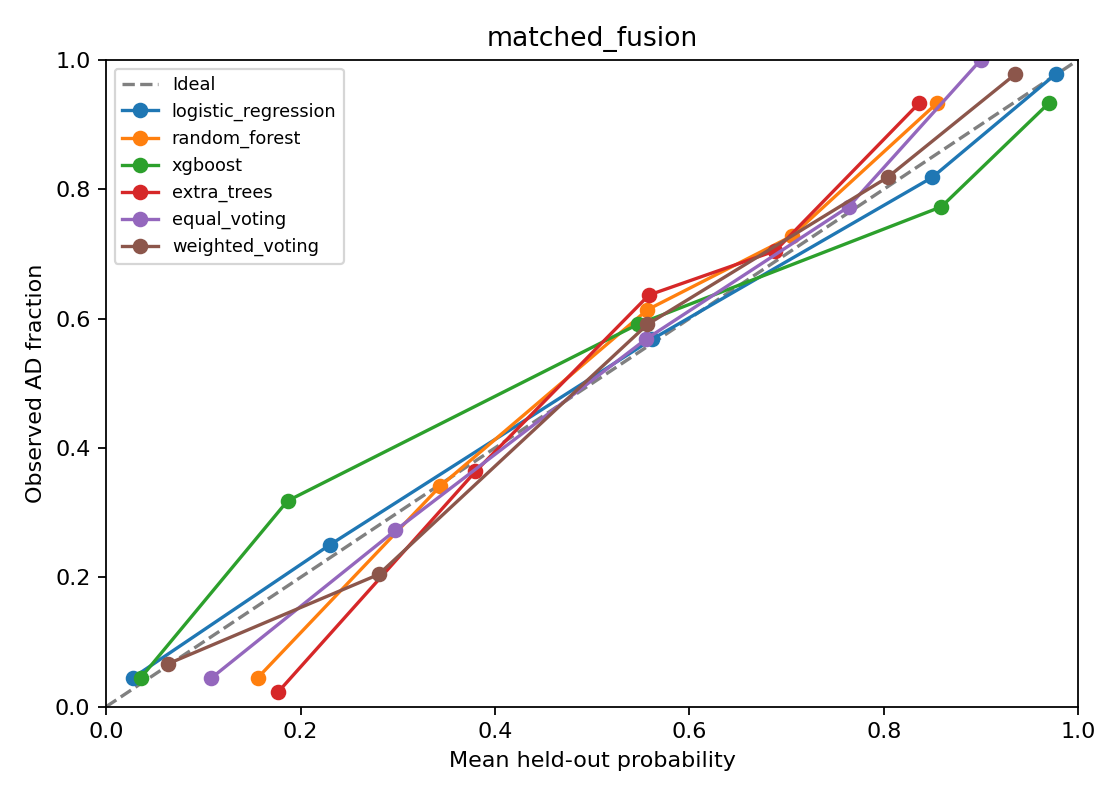

# Exploratory ensemble results

| Experiment | Model | N | Accuracy | AUROC | Average precision | Brier |
|---|---|---:|---:|---:|---:|---:|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 |
| clinical_reference | random_forest | 589 | 84.0% | 0.905 | 0.849 | 0.120 |
| clinical_reference | xgboost | 589 | 82.7% | 0.903 | 0.843 | 0.120 |
| clinical_reference | extra_trees | 589 | 83.4% | 0.903 | 0.845 | 0.124 |
| clinical_reference | equal_voting | 589 | 83.7% | 0.913 | 0.862 | 0.113 |
| clinical_reference | weighted_voting | 589 | 84.6% | 0.912 | 0.865 | 0.112 |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 |
| matched_clinical | random_forest | 222 | 79.3% | 0.868 | 0.879 | 0.151 |
| matched_clinical | xgboost | 222 | 79.3% | 0.870 | 0.882 | 0.148 |
| matched_clinical | extra_trees | 222 | 77.5% | 0.864 | 0.874 | 0.157 |
| matched_clinical | equal_voting | 222 | 79.7% | 0.888 | 0.903 | 0.137 |
| matched_clinical | weighted_voting | 222 | 80.6% | 0.895 | 0.912 | 0.133 |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 |
| matched_fusion | random_forest | 222 | 79.3% | 0.874 | 0.887 | 0.149 |
| matched_fusion | xgboost | 222 | 81.5% | 0.888 | 0.897 | 0.139 |
| matched_fusion | extra_trees | 222 | 80.2% | 0.876 | 0.884 | 0.151 |
| matched_fusion | equal_voting | 222 | 82.4% | 0.902 | 0.916 | 0.130 |
| matched_fusion | weighted_voting | 222 | 82.9% | 0.906 | 0.921 | 0.125 |

## Reading these results

- Accuracy is the fraction of correct held-out predictions at threshold 0.5. All CSV rates use the 0-1 scale.
- Average precision is the non-interpolated AUPRC summary. Higher AUROC/AP and lower Brier are better.
- The four base models are refitted in this environment; compare ensembles with these same-run baselines.
- Saved original outer folds are reused. Weights or stacking coefficients are learned only within outer training participants.
- The earlier results motivated these experiments. They are exploratory reuse of an already inspected cohort, not independent confirmation.
- Paired differences are ensemble minus same-run Logistic Regression. Intervals condition on saved predictions, omit retraining uncertainty, and are not adjusted for multiple comparisons.
- Do not keep changing methods against these results and call the best score an unbiased final estimate.
- Clinical reference and matched experiments use different cohorts. The matched cohort is ADNI1 only.
- MRI/CSF remain unavailable for meaningful comparison. The endpoint remains provisional and complete-case selection limits generalizability.
- No higher score is guaranteed. An ensemble that does not beat Logistic Regression is a valid result.


In [6]:
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(pd.read_csv(REPORT / 'ensemble_parameters.csv').round(4))
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))
display(Markdown((REPORT / 'results.md').read_text()))


## Interpretation and next step

Record whether voting improves accuracy **without an unacceptable loss of sensitivity, specificity, or calibration**. Preserve negative findings. Then run `02_stacking.ipynb`, which uses the same cohort and outer folds.

The matched cohort contains 222 ADNI1 participants; the broader complete-clinical cohort contains 589 participants. The endpoint is provisional. Do not represent these runs as external validation or the unsupported four-modality study.

Heavy deep-learning architectures are a later experiment, not part of this notebook. More complexity is not guaranteed to help these small tabular cohorts.